# 팀 통일 평가지표로 단계별 재평가

팀에서 통일하기로 한 평가 방향: **"전체 성능이 높은 모델이 아니라, 운전상태 변화에 따른 오경보를 억제하면서 저강도·취약 구간의 미탐을 줄이는 모델"**.
그 기준으로 우리 파이프라인의 단계별 결과(기준선 → 2단계 pad-aware → 3단계 후처리)가 어떻게 보이는지 다시 계산한다.

## 지표 정의 (팀 문서 그대로, 구현 세부는 각 셀에)
| 지표 | 정의 | 구현 |
|---|---|---|
| severity | 정상 분포 기준 각 변수의 z-score를 3채널 유클리드 거리로 합친 값 (row 단위) | `sqrt(z_AI0² + z_AI1² + z_AI2²)`, mu/sigma는 팀 정의대로 **normal 전체**의 원본 값 |
| severity bin | low 0~1.5 / mid 1.5~3 / high 3~6 / extreme 6+ | `pd.cut(bins=[0,1.5,3,6,100])` |
| Low-severity Recall | severity **1.5~3.0** 구간의 outlier 행에서의 recall | 팀 문서의 "severity 1.5~3.0 구간" 그대로 |
| FPR | 정상 val에서 양성 판정 비율 | FP / val 행 수 |
| Worst Mode FPR | 운전 상태별 FPR 중 최대 | 운전 상태 = 저진폭(01:00:18~01:12:04) / 정상진폭, 시각 기준 |
| Worst Phase Recall | 구간별 recall 중 최소 | **가정**: phase = 이상 이벤트 시간 3등분(초반/중반/후반). 갭 직후 위치별 recall도 함께 제시 |
| RFR | 기존 모델의 FN 중 새로 탐지한 수 ÷ 새로 생긴 FP 수 | 단계 간 비교 (기준선→2단계, 2단계→3단계) |

> 팀 표의 LSTM-AE / CNN-AE 수치와 직접 비교하려면 같은 분할·같은 임계값 규칙이어야 한다. 이 노트북 수치는 우리 분할(normal 시간순 80/20, 임계값 val p99) 기준이다.

## 0. CONFIG · seed

In [1]:
import os, random, math, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from sklearn.metrics import roc_auc_score, average_precision_score, precision_recall_curve, f1_score, precision_score, recall_score
from sklearn.ensemble import IsolationForest

%matplotlib inline
warnings.filterwarnings("ignore")

CONFIG = {
    # ── 경로 ──
    "NORMAL_PATH": "press_data_normal.csv",
    "OUTLIER_PATH": "outlier_data.csv",
    "OUT_DIR": "patchtst_outputs_team_eval", # 팀 지표 재평가 전용 출력 폴더
    # ── 컬럼 ──
    "TIME_COL": "TimeStamp",
    "LABEL_COL": "Equipment_state",
    "CHANNELS": ["AI0_Vibration", "AI1_Vibration", "AI2_Current"],   # 원본 센서 3개
    # ── 전처리 ──
    "NOMINAL_DT": 0.1,       # 명목 샘플링 주기(초). EDA에서 중앙값 0.1s 확인
    "GAP_FACTOR": 10,        # 중앙값의 10배(=1초) 넘는 간격이면 세그먼트를 끊는다
    "MAX_INTERP": 3,         # 이 샘플 수 이하의 짧은 결측만 선형 보간
    "TRAIN_RATIO": 0.8,      # normal 앞 80%를 train, 뒤 20%를 val (시간순)
    # ── 윈도우 ──
    # EDA: 세그먼트(버스트) 최대 길이가 50행(5초)이므로 윈도우는 50 이하여야 한다
    "WINDOW": 32,            # 윈도우 길이(샘플) = 3.2초
    "STRIDE": 4,             # 슬라이딩 간격
    "MIN_SEG_INFER": 8,      # 추론 시 이보다 짧은 세그먼트는 score를 매기지 않는다(패딩 한계)
    # ── 파생 변수 ──
    "use_features": True,    # True: 원본+파생 / False: 원본만  (6절에서 둘 다 비교한다)
    "ROLL_WIN": 10,          # 이동 통계 윈도우(샘플) = 1초
    # ── PatchTST ──
    "PATCH_LEN": 4,          # 패치 길이. (WINDOW-PATCH_LEN) % PATCH_STRIDE == 0 이어야 한다
    "PATCH_STRIDE": 4,       # = PATCH_LEN → 겹치지 않는 패치 (마스킹 시 정보 누출 방지)
    "D_MODEL": 64,           # 데이터 2만 행 → 소형 모델
    "N_HEADS": 4,
    "N_LAYERS": 2,
    "D_FF": 128,
    "DROPOUT": 0.1,
    "MASK_RATIO": 0.4,       # 학습 시 가리는 패치 비율 (PatchTST self-supervised 방식)
    "N_INFER_MASKS": 8,      # 추론 시 서로 다른 마스크 개수 (평균 내어 score 안정화)
    # ── 학습 ──
    "BATCH_SIZE": 64,
    "EPOCHS": 60,
    "LR": 1e-3,
    "PATIENCE": 8,           # val loss가 이 epoch 동안 안 좋아지면 중단
    "SEED": 42,
}
assert (CONFIG["WINDOW"] - CONFIG["PATCH_LEN"]) % CONFIG["PATCH_STRIDE"] == 0, "패치가 윈도우를 정확히 덮어야 한다"
os.makedirs(CONFIG["OUT_DIR"], exist_ok=True)


def set_seed(seed: int) -> None:
    """random / numpy / torch / cuda seed를 모두 고정한다. cudnn도 결정론 모드로 둔다."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True   # 같은 입력 → 같은 출력 (속도는 약간 손해)
    torch.backends.cudnn.benchmark = False


set_seed(CONFIG["SEED"])
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("torch", torch.__version__, "| device:", DEVICE)

# 그림 색: 정상=파랑, 이상=주황 (고정 순서, 색약 대비 검증된 조합). 임계값/경고=빨강
COLOR = {"normal": "#2a78d6", "outlier": "#eb6834", "thr": "#e34948", "gray": "#9a9a9a", "recon": "#2f9e6f"}
plt.rcParams.update({"axes.unicode_minus": False, "figure.dpi": 100})

torch 2.13.0+cu126 | device: cuda


## 1. 데이터 로드 · 전처리 (기준선과 동일)

In [2]:
def load_raw(path: str, cfg: dict) -> pd.DataFrame:
    """csv를 읽고 인덱스 컬럼 제거, 시간 컬럼을 datetime으로 변환한다."""
    df = pd.read_csv(path)
    unnamed = [c for c in df.columns if str(c).startswith("Unnamed")]   # 저장 시 섞인 인덱스 컬럼
    df = df.drop(columns=unnamed)
    df[cfg["TIME_COL"]] = pd.to_datetime(df[cfg["TIME_COL"]])
    return df


raw_normal = load_raw(CONFIG["NORMAL_PATH"], CONFIG)
raw_outlier = load_raw(CONFIG["OUTLIER_PATH"], CONFIG)

for name, df in [("normal", raw_normal), ("outlier", raw_outlier)]:
    tc = CONFIG["TIME_COL"]
    print(f"[{name}] shape={df.shape} | 기간 {df[tc].min()} ~ {df[tc].max()} "
          f"| 라벨 분포 {df[CONFIG['LABEL_COL']].value_counts().to_dict()}")

# 파일 자체가 라벨이다: normal 파일 = 전부 0, outlier 파일 = 전부 1 → 행 단위 라벨은 파일 단위 라벨과 같다
print(f"\n불균형 비율: {len(raw_normal)} : {len(raw_outlier)} = {len(raw_normal)/len(raw_outlier):.1f} : 1")

[normal] shape=(20000, 5) | 기간 2022-07-12 00:00:00.019000 ~ 2022-07-12 01:16:55.828000 | 라벨 분포 {0: 20000}
[outlier] shape=(600, 5) | 기간 2022-07-17 10:51:07.943000 ~ 2022-07-17 10:53:53.540000 | 라벨 분포 {1: 600}

불균형 비율: 20000 : 600 = 33.3 : 1


In [3]:
def resolve_duplicate_timestamps(df: pd.DataFrame, cfg: dict) -> pd.DataFrame:
    """동일 타임스탬프 행을 판별(완전 중복 / 값 충돌)하고 제거 또는 평균 병합한다."""
    tc, chs = cfg["TIME_COL"], cfg["CHANNELS"]
    n_ts_dup = int(df[tc].duplicated().sum())                 # 시각이 같은 '추가' 행 수
    n_full_dup = int(df.duplicated(subset=[tc] + chs).sum())  # 시각+값이 모두 같은 추가 행 수
    n_conflict = n_ts_dup - n_full_dup                        # 시각만 같고 값이 다른 행 수
    print(f"  동일 시각 행: {n_ts_dup}건 → 완전 중복 {n_full_dup}건 (제거), 값 충돌 {n_conflict}건 (평균 병합)")

    before = len(df)
    df = df.drop_duplicates(subset=[tc] + chs)                          # 완전 중복 제거
    df = df.groupby(tc, as_index=False)[chs].mean()                     # 남은 동일 시각은 평균 병합
    print(f"  행 수: {before} → {len(df)}")
    return df


print("[normal]");  normal_p = resolve_duplicate_timestamps(raw_normal, CONFIG)
print("[outlier]"); outlier_p = resolve_duplicate_timestamps(raw_outlier, CONFIG)

[normal]
  동일 시각 행: 1건 → 완전 중복 1건 (제거), 값 충돌 0건 (평균 병합)
  행 수: 20000 → 19999
[outlier]
  동일 시각 행: 0건 → 완전 중복 0건 (제거), 값 충돌 0건 (평균 병합)
  행 수: 600 → 600


In [4]:
def sort_by_time(df: pd.DataFrame, cfg: dict) -> pd.DataFrame:
    """시간순 정렬 + reset_index. 정렬 전후로 순서가 바뀐 행 수를 출력한다."""
    tc = cfg["TIME_COL"]
    n_unsorted = int((df[tc].diff().dt.total_seconds() < 0).sum())   # 시간이 거꾸로 가는 지점 수
    df = df.sort_values(tc).reset_index(drop=True)
    print(f"  시간 역행 지점 {n_unsorted}건 → 정렬 완료, 행 {len(df)}")
    return df


print("[normal]");  normal_p = sort_by_time(normal_p, CONFIG)
print("[outlier]"); outlier_p = sort_by_time(outlier_p, CONFIG)

[normal]
  시간 역행 지점 0건 → 정렬 완료, 행 19999
[outlier]
  시간 역행 지점 0건 → 정렬 완료, 행 600


In [5]:
def assign_segments(df: pd.DataFrame, cfg: dict, gap_sec: float, verbose: bool = True) -> pd.DataFrame:
    """앞 행과의 간격이 gap_sec를 넘는 지점마다 seg_id를 1씩 올려 세그먼트를 나눈다."""
    tc = cfg["TIME_COL"]
    dt = df[tc].diff().dt.total_seconds().fillna(0.0)
    df = df.copy()
    df["seg_id"] = (dt > gap_sec).cumsum().astype(int)
    if verbose:
        seg_len = df.groupby("seg_id").size()
        gaps = dt[dt > gap_sec]
        print(f"  갭 기준 {gap_sec:.2f}s | 세그먼트 {len(seg_len)}개 | 길이 min/median/max = "
              f"{seg_len.min()}/{int(seg_len.median())}/{seg_len.max()}행 | "
              f"갭 크기 min/median/max = {gaps.min():.2f}/{gaps.median():.2f}/{gaps.max():.2f}s")
    return df


GAP_SEC = CONFIG["NOMINAL_DT"] * CONFIG["GAP_FACTOR"]
print("[normal]");  normal_p = assign_segments(normal_p, CONFIG, GAP_SEC)
print("[outlier]"); outlier_p = assign_segments(outlier_p, CONFIG, GAP_SEC)

[normal]
  갭 기준 1.00s | 세그먼트 599개 | 길이 min/median/max = 1/37/50행 | 갭 크기 min/median/max = 1.54/4.22/16.64s
[outlier]
  갭 기준 1.00s | 세그먼트 21개 | 길이 min/median/max = 3/28/50행 | 갭 크기 min/median/max = 1.78/5.35/8.57s


In [6]:
def resample_segments(df: pd.DataFrame, cfg: dict) -> pd.DataFrame:
    """세그먼트별로 0.1초 격자에 맞추고, 짧은 결측만 선형 보간한다. 긴 결측은 삭제한다."""
    tc, chs, dt, max_interp = cfg["TIME_COL"], cfg["CHANNELS"], cfg["NOMINAL_DT"], cfg["MAX_INTERP"]
    out, n_interp, n_dropped, n_snap = [], 0, 0, 0
    for sid, seg in df.groupby("seg_id"):
        t0 = seg[tc].iloc[0]
        k = np.round((seg[tc] - t0).dt.total_seconds() / dt).astype(int)   # 격자 위치(정수)
        seg = seg.assign(k=k.values)
        g = seg.groupby("k")[chs].mean()                # 같은 격자로 스냅된 행은 평균
        g[tc] = seg.groupby("k")[tc].first()            # 실제 행은 원래 시각을 유지(제출 시 병합 키)
        n_snap += len(seg) - len(g)
        g = g.reindex(pd.RangeIndex(0, int(g.index.max()) + 1))   # 빠진 격자를 NaN 행으로 채움
        is_real = g[chs[0]].notna()
        # 결측 run 길이를 계산해 짧은 run만 보간 대상으로 표시
        isna = ~is_real
        run_id = (isna != isna.shift()).cumsum()
        run_len = isna.groupby(run_id).transform("size")
        fill_ok = isna & (run_len <= max_interp)
        interp = g[chs].interpolate("linear", limit_area="inside")
        g.loc[fill_ok, chs] = interp.loc[fill_ok, chs]
        n_interp += int(fill_ok.sum())
        still_na = g[chs[0]].isna()
        n_dropped += int(still_na.sum())
        g = g[~still_na].copy()
        # 보간된 행의 시각은 격자 시각으로 채운다
        grid_time = t0 + pd.to_timedelta(np.round(g.index.values * dt, 3), unit="s")
        g[tc] = g[tc].fillna(pd.Series(grid_time, index=g.index))
        g["is_interp"] = ~is_real[g.index]
        out.append(g[[tc] + chs + ["is_interp"]])
    res = pd.concat(out, ignore_index=True)
    print(f"  행 {len(df)} → {len(res)} | 같은 격자로 병합 {n_snap}행 | 보간 {n_interp}행 | 긴 결측으로 삭제 {n_dropped}격자")
    # 보간되지 않은 긴 결측이 남긴 틈에서 세그먼트를 다시 끊는다(2차 분리)
    res = assign_segments(res, cfg, gap_sec=dt * 1.5, verbose=True)
    return res


print("[normal]");  normal_p = resample_segments(normal_p, CONFIG)
print("[outlier]"); outlier_p = resample_segments(outlier_p, CONFIG)

# 파일 = 라벨 (normal 0, outlier 1)
normal_p["y"] = 0
outlier_p["y"] = 1

# 리샘플 결과 확인: 세그먼트 안의 간격은 전부 0.1초여야 한다
for name, df in [("normal", normal_p), ("outlier", outlier_p)]:
    d = df.groupby("seg_id")[CONFIG["TIME_COL"]].diff().dt.total_seconds().dropna()
    print(f"  {name}: 세그먼트 내부 간격 종류 = {sorted(d.round(3).unique())}")

[normal]


  행 19999 → 19999 | 같은 격자로 병합 0행 | 보간 0행 | 긴 결측으로 삭제 0격자
  갭 기준 0.15s | 세그먼트 599개 | 길이 min/median/max = 1/37/50행 | 갭 크기 min/median/max = 1.54/4.22/16.64s
[outlier]
  행 600 → 600 | 같은 격자로 병합 0행 | 보간 0행 | 긴 결측으로 삭제 0격자
  갭 기준 0.15s | 세그먼트 21개 | 길이 min/median/max = 3/28/50행 | 갭 크기 min/median/max = 1.78/5.35/8.57s
  normal: 세그먼트 내부 간격 종류 = [0.1]
  outlier: 세그먼트 내부 간격 종류 = [0.1]


In [7]:
def time_split(df: pd.DataFrame, ratio: float) -> pd.DataFrame:
    """앞 ratio 비율은 train, 나머지는 val. 경계를 다음 세그먼트 시작으로 이동한다."""
    df = df.copy()
    target = int(len(df) * ratio)
    seg_starts = df.index[df["seg_id"] != df["seg_id"].shift()]      # 각 세그먼트의 첫 행 위치
    split_at = int(seg_starts[seg_starts >= target][0])
    df["split"] = np.where(df.index < split_at, "train", "val")
    tc = CONFIG["TIME_COL"]
    for s in ["train", "val"]:
        part = df[df["split"] == s]
        print(f"  {s}: {len(part)}행, {part['seg_id'].nunique()}세그먼트, {part[tc].min().time()} ~ {part[tc].max().time()}")
    return df


normal_p = time_split(normal_p, CONFIG["TRAIN_RATIO"])
outlier_p["split"] = "test"

  train: 16009행, 481세그먼트, 00:00:00.019000 ~ 01:01:01.732000
  val: 3990행, 118세그먼트, 01:01:04.524000 ~ 01:16:55.828000


In [8]:
FEATURE_COLS = []   # 파생 변수 이름 목록 (아래에서 채움)


def add_features(df: pd.DataFrame, cfg: dict) -> pd.DataFrame:
    """세그먼트 내부에서만 차분 / 이동 std / 전류 이동 RMS를 계산한다."""
    df = df.copy()
    g = df.groupby("seg_id")
    w = cfg["ROLL_WIN"]
    cols = []
    for ch in cfg["CHANNELS"]:
        df[f"{ch}_diff"] = g[ch].diff().fillna(0.0)                                          # 세그먼트 첫 행은 0
        df[f"{ch}_rstd"] = g[ch].transform(lambda s: s.rolling(w, min_periods=2).std()).fillna(0.0)
        cols += [f"{ch}_diff", f"{ch}_rstd"]
    df["AI2_Current_rms"] = g["AI2_Current"].transform(lambda s: np.sqrt((s ** 2).rolling(w, min_periods=1).mean()))
    cols.append("AI2_Current_rms")
    return df, cols


normal_p, FEATURE_COLS = add_features(normal_p, CONFIG)
outlier_p, _ = add_features(outlier_p, CONFIG)
print("파생 변수:", FEATURE_COLS)

# 세그먼트 경계를 무시하고 차분하면 어떤 일이 생기는지 확인
naive_diff = normal_p["AI2_Current"].diff().abs()                     # 경계 무시
seg_diff = normal_p["AI2_Current_diff"].abs()                          # 세그먼트 내부
boundary = normal_p["seg_id"] != normal_p["seg_id"].shift()
print(f"경계 무시 차분의 99.9% 분위: 내부 {seg_diff.quantile(0.999):.1f} vs 경계에서 {naive_diff[boundary].quantile(0.999):.1f}"
      f" → 경계 행 {int(boundary.sum())}개가 가짜 급변으로 잡힌다")

파생 변수: ['AI0_Vibration_diff', 'AI0_Vibration_rstd', 'AI1_Vibration_diff', 'AI1_Vibration_rstd', 'AI2_Current_diff', 'AI2_Current_rstd', 'AI2_Current_rms']
경계 무시 차분의 99.9% 분위: 내부 94.2 vs 경계에서 460.6 → 경계 행 599개가 가짜 급변으로 잡힌다


In [9]:
def fit_stats(df: pd.DataFrame, cols: list) -> tuple:
    """train 행에서만 mean/std를 계산한다. std가 0인 컬럼은 나눗셈 보호."""
    mu = df[cols].mean()
    sd = df[cols].std().clip(lower=1e-6)
    return mu, sd


def apply_norm(df: pd.DataFrame, cols: list, mu, sd) -> np.ndarray:
    """(x - mu) / sd → float32 배열 [N, C]"""
    return ((df[cols] - mu) / sd).to_numpy(dtype=np.float32)


ALL_COLS = CONFIG["CHANNELS"] + FEATURE_COLS
train_rows = normal_p[normal_p["split"] == "train"]
MU, SD = fit_stats(train_rows, ALL_COLS)
print("train 통계 (원본 채널만 표시):")
print(pd.DataFrame({"mean": MU, "std": SD}).loc[CONFIG["CHANNELS"]].round(4))

# 통계 누수 검증: outlier로 정규화한 값과 train으로 정규화한 값의 스케일 차이
mu_leak, sd_leak = fit_stats(outlier_p, CONFIG["CHANNELS"])
print("\n만약 outlier 통계로 정규화했다면 |z| 평균:",
      ((outlier_p[CONFIG["CHANNELS"]] - mu_leak) / sd_leak).abs().mean().round(2).to_dict())
print("train 통계로 정규화한 outlier |z| 평균   :",
      ((outlier_p[CONFIG["CHANNELS"]] - MU[CONFIG["CHANNELS"]]) / SD[CONFIG["CHANNELS"]]).abs().mean().round(2).to_dict())

train 통계 (원본 채널만 표시):
                 mean       std
AI0_Vibration -0.0001    0.0743
AI1_Vibration -0.0000    0.1277
AI2_Current    1.2750  127.7931

만약 outlier 통계로 정규화했다면 |z| 평균: {'AI0_Vibration': 0.62, 'AI1_Vibration': 0.78, 'AI2_Current': 0.77}
train 통계로 정규화한 outlier |z| 평균   : {'AI0_Vibration': 3.75, 'AI1_Vibration': 1.47, 'AI2_Current': 0.99}


## 2. 함수 정의 (기준선 + 2단계 pad-aware)

In [10]:
def make_windows(df: pd.DataFrame, Z: np.ndarray, cfg: dict, pad_short: bool, verbose: bool = True):
    """세그먼트 안에서 슬라이딩 윈도우를 만든다.
    반환: X [n, W, C] (정규화 값), IDX [n, W] (df 행 위치, 패딩은 -1)"""
    W, S, min_len = cfg["WINDOW"], cfg["STRIDE"], cfg["MIN_SEG_INFER"]
    X, IDX = [], []
    n_drop_seg = n_drop_rows = n_pad_seg = 0
    for sid, pos in df.groupby("seg_id").indices.items():     # pos: 이 세그먼트 행들의 위치 배열
        L = len(pos)
        if L >= W:
            starts = list(range(0, L - W + 1, S))
            if starts[-1] != L - W:
                starts.append(L - W)                            # 끝 맞춤 윈도우
            for s in starts:
                X.append(Z[pos[s:s + W]]); IDX.append(pos[s:s + W])
        elif pad_short and L >= min_len:
            pad = W - L
            X.append(np.concatenate([Z[pos], np.repeat(Z[pos[-1:]], pad, axis=0)]))   # 마지막 값 반복
            IDX.append(np.concatenate([pos, -np.ones(pad, dtype=int)]))
            n_pad_seg += 1
        else:
            n_drop_seg += 1; n_drop_rows += L
    X = np.stack(X).astype(np.float32); IDX = np.stack(IDX)
    if verbose:
        print(f"  윈도우 {len(X)}개 (shape {X.shape}) | 패딩 세그먼트 {n_pad_seg}개 | "
              f"버린 세그먼트 {n_drop_seg}개 ({n_drop_rows}행)")
    return X, IDX


def build_dataset(cols: list):
    """정규화 → 윈도우 생성까지. 학습용(train만, 패딩 없음)과 추론용(전체, 패딩 허용)을 함께 만든다."""
    Z_n = apply_norm(normal_p, cols, MU[cols], SD[cols])
    Z_o = apply_norm(outlier_p, cols, MU[cols], SD[cols])
    print(" [학습용 normal]");  X_all, IDX_all = make_windows(normal_p, Z_n, CONFIG, pad_short=False)
    split_arr = normal_p["split"].to_numpy()
    is_train = np.all(split_arr[IDX_all] == "train", axis=1)      # 윈도우 전체가 train에 속해야 함
    is_val = np.all(split_arr[IDX_all] == "val", axis=1)
    print(f"   → train 윈도우 {is_train.sum()}개, val 윈도우 {is_val.sum()}개, 경계 걸침 {(~is_train & ~is_val).sum()}개")
    print(" [추론용 normal]");  Xn_inf, IDXn_inf = make_windows(normal_p, Z_n, CONFIG, pad_short=True)
    print(" [추론용 outlier]"); Xo_inf, IDXo_inf = make_windows(outlier_p, Z_o, CONFIG, pad_short=True)
    return {"cols": cols, "X_train": X_all[is_train], "X_val": X_all[is_val],
            "Xn_inf": Xn_inf, "IDXn_inf": IDXn_inf, "Xo_inf": Xo_inf, "IDXo_inf": IDXo_inf}

In [11]:
class RevIN(nn.Module):
    """Reversible Instance Normalization.
    윈도우마다 채널별 mean/std로 정규화하고, 출력에서 되돌린다.
    → 정상/이상이 다른 날짜·부하에서 수집되어 생기는 '절대 수준 차이'를 제거하고 파형(형태)만 보게 한다.
    입력 [B, L, C] → 출력 [B, L, C]"""
    def __init__(self, n_ch: int, eps: float = 1e-5):
        super().__init__()
        self.eps = eps
        self.gamma = nn.Parameter(torch.ones(n_ch))    # 채널별 학습 가능한 scale
        self.beta = nn.Parameter(torch.zeros(n_ch))    # 채널별 학습 가능한 shift

    def forward(self, x: torch.Tensor, mode: str) -> torch.Tensor:
        if mode == "norm":
            self.mean = x.mean(dim=1, keepdim=True).detach()                        # [B, 1, C]
            self.std = torch.sqrt(x.var(dim=1, keepdim=True, unbiased=False) + self.eps).detach()
            return (x - self.mean) / self.std * self.gamma + self.beta
        elif mode == "denorm":
            return (x - self.beta) / (self.gamma + self.eps) * self.std + self.mean
        raise ValueError(mode)


class Patching(nn.Module):
    """[B, L, C] → [B*C, N, P]  (N = 패치 수, P = 패치 길이). 채널을 배치 차원으로 합쳐 채널 독립 처리."""
    def __init__(self, patch_len: int, stride: int):
        super().__init__()
        self.P, self.S = patch_len, stride

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        B, L, C = x.shape
        x = x.permute(0, 2, 1)                              # [B, C, L]
        x = x.unfold(dimension=2, size=self.P, step=self.S) # [B, C, N, P]
        return x.reshape(B * C, x.shape[2], self.P)         # [B*C, N, P]


class PatchTSTReconstructor(nn.Module):
    """마스킹 재구성용 PatchTST.
    forward(x [B, L, C], patch_mask [B*C, N] or None) → 재구성 x_hat [B, L, C]"""
    def __init__(self, n_ch: int, cfg: dict):
        super().__init__()
        L, P, S, D = cfg["WINDOW"], cfg["PATCH_LEN"], cfg["PATCH_STRIDE"], cfg["D_MODEL"]
        self.n_ch, self.L, self.P, self.S = n_ch, L, P, S
        self.N = (L - P) // S + 1                            # 패치 수
        self.revin = RevIN(n_ch)
        self.patching = Patching(P, S)
        self.proj = nn.Linear(P, D)                          # 패치 → 임베딩  [B*C, N, P] → [B*C, N, D]
        self.pos = nn.Parameter(torch.randn(1, self.N, D) * 0.02)   # 학습 가능한 위치 임베딩
        self.mask_token = nn.Parameter(torch.zeros(1, 1, D))        # 가려진 패치 자리에 넣는 토큰
        layer = nn.TransformerEncoderLayer(d_model=D, nhead=cfg["N_HEADS"], dim_feedforward=cfg["D_FF"],
                                           dropout=cfg["DROPOUT"], batch_first=True, activation="gelu")
        self.encoder = nn.TransformerEncoder(layer, num_layers=cfg["N_LAYERS"])
        self.head = nn.Sequential(nn.Flatten(start_dim=1), nn.Dropout(cfg["DROPOUT"]),
                                  nn.Linear(self.N * D, L))   # [B*C, N*D] → [B*C, L]

    def forward(self, x: torch.Tensor, patch_mask: torch.Tensor = None) -> torch.Tensor:
        B, L, C = x.shape
        x = self.revin(x, "norm")                             # [B, L, C]
        p = self.patching(x)                                  # [B*C, N, P]
        z = self.proj(p) + self.pos                           # [B*C, N, D]
        if patch_mask is not None:                            # 가려진 패치의 임베딩을 mask_token으로 교체
            m = patch_mask.unsqueeze(-1).bool()               # [B*C, N, 1]
            z = torch.where(m, self.mask_token.expand_as(z), z)
        z = self.encoder(z)                                   # [B*C, N, D]
        out = self.head(z)                                    # [B*C, L]
        out = out.view(B, C, L).permute(0, 2, 1)              # [B, L, C]
        return self.revin(out, "denorm")

    def patch_to_pos_mask(self, patch_mask: torch.Tensor, B: int) -> torch.Tensor:
        """패치 마스크 [B*C, N] → 위치 마스크 [B, L, C] (가려진 패치가 덮는 시점은 1)"""
        BC, N = patch_mask.shape
        pos = torch.zeros(BC, self.L, device=patch_mask.device)
        for n in range(N):
            seg = pos[:, n * self.S: n * self.S + self.P]
            pos[:, n * self.S: n * self.S + self.P] = torch.maximum(seg, patch_mask[:, n:n + 1])
        return pos.view(B, self.n_ch, self.L).permute(0, 2, 1)


def random_patch_mask(BC: int, N: int, ratio: float, gen: torch.Generator, device) -> torch.Tensor:
    """시퀀스마다 round(ratio*N)개의 패치를 무작위로 가린다. 반환 [BC, N] float(1=가림)"""
    k = max(1, int(round(ratio * N)))
    order = torch.rand(BC, N, generator=gen).argsort(dim=1)
    mask = torch.zeros(BC, N)
    mask.scatter_(1, order[:, :k], 1.0)
    return mask.to(device)


# 모델 크기 확인
_tmp = PatchTSTReconstructor(n_ch=len(ALL_COLS), cfg=CONFIG)
n_params = sum(p.numel() for p in _tmp.parameters())
print(f"패치 수 N = {_tmp.N}, 파라미터 수 = {n_params:,}")
with torch.no_grad():   # shape 확인용 더미 forward
    xb = torch.randn(2, CONFIG["WINDOW"], len(ALL_COLS))
    mk = random_patch_mask(2 * len(ALL_COLS), _tmp.N, CONFIG["MASK_RATIO"], torch.Generator().manual_seed(0), "cpu")
    print("입력", tuple(xb.shape), "→ 출력", tuple(_tmp(xb, mk).shape), "| 위치 마스크", tuple(_tmp.patch_to_pos_mask(mk, 2).shape))
del _tmp

패치 수 N = 8, 파라미터 수 = 84,276
입력 (2, 32, 10) → 출력 (2, 32, 10) | 위치 마스크 (2, 32, 10)


In [12]:
def masked_mse(x_hat, x, pos_mask):
    """가려진 위치에서만 MSE. pos_mask [B, L, C] (1=가림)"""
    return (((x_hat - x) ** 2) * pos_mask).sum() / pos_mask.sum().clamp(min=1.0)


def run_epoch(model, X, cfg, optimizer=None, gen=None):
    """한 epoch. optimizer가 None이면 평가 모드(가중치 갱신 없음)."""
    train = optimizer is not None
    model.train(train)
    n_ch, bs = X.shape[2], cfg["BATCH_SIZE"]
    order = torch.randperm(len(X), generator=gen) if train else torch.arange(len(X))
    total, count = 0.0, 0
    for i in range(0, len(X), bs):
        xb = torch.from_numpy(X[order[i:i + bs].numpy()]).to(DEVICE)
        mask = random_patch_mask(xb.shape[0] * n_ch, model.N, cfg["MASK_RATIO"], gen, DEVICE)
        pos_mask = model.patch_to_pos_mask(mask, xb.shape[0])
        with torch.set_grad_enabled(train):
            loss = masked_mse(model(xb, mask), xb, pos_mask)
        if train:
            optimizer.zero_grad(); loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)   # Transformer 학습 안정화
            optimizer.step()
        total += loss.item() * len(xb); count += len(xb)
    return total / count


def train_model(X_train, X_val, cfg, tag: str):
    """학습 + early stopping. 최적 가중치를 OUT_DIR/patchtst_{tag}.pt 에 저장하고 학습 곡선을 반환한다."""
    set_seed(cfg["SEED"])
    model = PatchTSTReconstructor(n_ch=X_train.shape[2], cfg=cfg).to(DEVICE)
    opt = torch.optim.AdamW(model.parameters(), lr=cfg["LR"], weight_decay=1e-4)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=cfg["EPOCHS"])
    gen_train = torch.Generator().manual_seed(cfg["SEED"])
    hist, best, bad, best_state = {"train": [], "val": []}, float("inf"), 0, None
    path = os.path.join(cfg["OUT_DIR"], f"patchtst_{tag}.pt")
    t0 = time.time()
    for ep in range(1, cfg["EPOCHS"] + 1):
        tr = run_epoch(model, X_train, cfg, opt, gen_train)
        va = run_epoch(model, X_val, cfg, None, torch.Generator().manual_seed(cfg["SEED"] + 1))  # val 마스크 고정
        sched.step()
        hist["train"].append(tr); hist["val"].append(va)
        if va < best - 1e-6:
            best, bad = va, 0
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
            torch.save(best_state, path)
        else:
            bad += 1
        if ep % 5 == 0 or ep == 1:
            print(f"  [{tag}] epoch {ep:3d} | train {tr:.4f} | val {va:.4f} | best {best:.4f}")
        if bad >= cfg["PATIENCE"]:
            print(f"  [{tag}] early stopping at epoch {ep} (best val {best:.4f})")
            break
    model.load_state_dict(best_state)
    print(f"  [{tag}] 학습 시간 {time.time() - t0:.1f}s, 가중치 저장 → {path}")
    return model, hist

In [13]:
@torch.no_grad()
def reconstruction_errors(model, X: np.ndarray, cfg: dict) -> np.ndarray:
    """윈도우별·시점별·채널별 재구성 오차 [n, L, C]. 여러 마스크에서 '가려졌을 때'의 오차를 평균한다."""
    model.eval()
    n_ch, bs, K = X.shape[2], cfg["BATCH_SIZE"] * 4, cfg["N_INFER_MASKS"]
    gen = torch.Generator().manual_seed(cfg["SEED"] + 7)      # 추론 마스크도 고정 → 재현 가능
    out = []
    for i in range(0, len(X), bs):
        xb = torch.from_numpy(X[i:i + bs]).to(DEVICE)
        B = xb.shape[0]
        sum_masked = torch.zeros_like(xb); cnt = torch.zeros_like(xb); sum_all = torch.zeros_like(xb)
        for _ in range(K):
            mask = random_patch_mask(B * n_ch, model.N, cfg["MASK_RATIO"], gen, DEVICE)
            pm = model.patch_to_pos_mask(mask, B)
            e = (model(xb, mask) - xb) ** 2
            sum_masked += e * pm; cnt += pm; sum_all += e
        err = torch.where(cnt > 0, sum_masked / cnt.clamp(min=1), sum_all / K)   # 한 번도 안 가려진 시점은 전체 평균
        out.append(err.cpu().numpy())
    return np.concatenate(out)


def aggregate_rows(err: np.ndarray, IDX: np.ndarray, n_rows: int) -> np.ndarray:
    """윈도우 오차 [n, L, C] → 행별 오차 [n_rows, C]. 겹치는 윈도우는 평균, 패딩(-1)은 제외, 미커버 행은 NaN."""
    C = err.shape[2]
    sums = np.zeros((n_rows, C)); cnt = np.zeros(n_rows)
    valid = IDX >= 0
    np.add.at(sums, IDX[valid], err[valid])
    np.add.at(cnt, IDX[valid], 1)
    row_err = np.full((n_rows, C), np.nan)
    row_err[cnt > 0] = sums[cnt > 0] / cnt[cnt > 0, None]
    return row_err


def score_patchtst(tag: str) -> dict:
    """normal(train/val)과 outlier 전체 행에 대해 채널별 오차와 score를 계산한다."""
    d, model = DATA[tag], MODELS[tag]
    err_n = aggregate_rows(reconstruction_errors(model, d["Xn_inf"], CONFIG), d["IDXn_inf"], len(normal_p))
    err_o = aggregate_rows(reconstruction_errors(model, d["Xo_inf"], CONFIG), d["IDXo_inf"], len(outlier_p))
    s_n, s_o = np.nanmean(err_n, axis=1), np.nanmean(err_o, axis=1)
    val_mask = (normal_p["split"] == "val").to_numpy()
    fill = np.nanmedian(s_n[val_mask])                     # score를 못 매긴 행(너무 짧은 세그먼트)은 val 중앙값 = "정상으로 간주"
    print(f"  [{tag}] score 없는 행: normal {np.isnan(s_n).sum()}, outlier {np.isnan(s_o).sum()} → val 중앙값 {fill:.4f}으로 채움")
    return {"err_n": err_n, "err_o": err_o,
            "scored_n": ~np.isnan(s_n), "scored_o": ~np.isnan(s_o),
            "score_n": np.where(np.isnan(s_n), fill, s_n), "score_o": np.where(np.isnan(s_o), fill, s_o),
            "cols": d["cols"]}

In [14]:
VAL_MASK = (normal_p["split"] == "val").to_numpy()
TRAIN_MASK = ~VAL_MASK


def thresholds_from_val(score_val: np.ndarray) -> dict:
    """라벨 없이 val 정상 score 분포에서 임계값을 정한다."""
    return {"val_p99": float(np.percentile(score_val, 99)),
            "val_mean+3sd": float(score_val.mean() + 3 * score_val.std())}


def best_f1_threshold(y: np.ndarray, s: np.ndarray) -> float:
    """라벨을 써서 F1이 최대가 되는 임계값 (낙관적 상한)."""
    p, r, t = precision_recall_curve(y, s)
    f1 = 2 * p[:-1] * r[:-1] / np.clip(p[:-1] + r[:-1], 1e-12, None)
    return float(t[int(np.argmax(f1))])


def evaluate(score_val: np.ndarray, score_out: np.ndarray, name: str) -> pd.DataFrame:
    """val 정상(0) + outlier(1)에 대해 AUROC / PR-AUC와 임계값별 F1을 계산한다."""
    y = np.r_[np.zeros(len(score_val)), np.ones(len(score_out))]
    s = np.r_[score_val, score_out]
    thr = thresholds_from_val(score_val); thr["best_f1"] = best_f1_threshold(y, s)
    rows = []
    for tname, t in thr.items():
        pred = (s >= t).astype(int)
        rows.append({"model": name, "threshold": tname, "thr_value": t,
                     "precision": precision_score(y, pred, zero_division=0), "recall": recall_score(y, pred),
                     "F1": f1_score(y, pred), "AUROC": roc_auc_score(y, s), "PR-AUC": average_precision_score(y, s),
                     "FP(val)": int(((pred == 1) & (y == 0)).sum()), "FN(out)": int(((pred == 0) & (y == 1)).sum())})
    return pd.DataFrame(rows), thr

In [15]:
class RevINMasked(RevIN):
    """RevIN과 같지만 valid [B, L, C] (1=실제 행) 가중치로 mean/std를 실제 행에서만 계산한다."""
    def forward(self, x, mode, valid=None):
        if mode == "norm":
            if valid is None:
                return super().forward(x, "norm")
            cnt = valid.sum(dim=1, keepdim=True).clamp(min=1.0)                      # [B, 1, C] 실제 행 수
            self.mean = ((x * valid).sum(dim=1, keepdim=True) / cnt).detach()
            var = (((x - self.mean) ** 2) * valid).sum(dim=1, keepdim=True) / cnt
            self.std = torch.sqrt(var + self.eps).detach()
            return (x - self.mean) / self.std * self.gamma + self.beta
        return super().forward(x, "denorm")


class PatchTSTPadAware(PatchTSTReconstructor):
    """패딩 패치를 attention에서 제외하는 PatchTST. pad_pos=None이면 기준선과 동일."""
    def __init__(self, n_ch, cfg):
        super().__init__(n_ch, cfg)
        self.revin = RevINMasked(n_ch)                                   # 실제 행 기준 정규화로 교체
        layer = nn.TransformerEncoderLayer(d_model=cfg["D_MODEL"], nhead=cfg["N_HEADS"], dim_feedforward=cfg["D_FF"],
                                           dropout=cfg["DROPOUT"], batch_first=True, activation="gelu")
        # key_padding_mask를 쓸 때 nested tensor 경로를 끄는 편이 재현성과 호환성에 안전
        self.encoder = nn.TransformerEncoder(layer, num_layers=cfg["N_LAYERS"], enable_nested_tensor=False)

    def pad_patches(self, pad_pos: torch.Tensor) -> torch.Tensor:
        """pad_pos [B, L, C] → pad_patch [B*C, N] (패치의 모든 위치가 패딩이면 True)"""
        return self.patching(pad_pos.float()).min(dim=-1).values.bool()

    def forward(self, x, patch_mask=None, pad_pos=None):
        B, L, C = x.shape
        valid = None if pad_pos is None else (~pad_pos).float()
        x = self.revin(x, "norm", valid)                                 # [B, L, C]
        z = self.proj(self.patching(x)) + self.pos                       # [B*C, N, D]
        if patch_mask is not None:
            z = torch.where(patch_mask.unsqueeze(-1).bool(), self.mask_token.expand_as(z), z)
        key_pad = None
        if pad_pos is not None:
            key_pad = self.pad_patches(pad_pos)                          # [B*C, N]
        z = self.encoder(z, src_key_padding_mask=key_pad)                # 패딩 패치는 key로 참조되지 않음
        if key_pad is not None:
            z = z.masked_fill(key_pad.unsqueeze(-1), 0.0)                # 패딩 패치의 출력도 head에 넘기지 않음
        out = self.head(z).view(B, C, L).permute(0, 2, 1)
        return self.revin(out, "denorm")


def random_patch_mask_valid(pad_patch: torch.Tensor, ratio: float, gen: torch.Generator) -> torch.Tensor:
    """실제 패치 중에서만 round(ratio × 실제 패치 수)개를 가린다. pad_patch [BC, N] (True=패딩)"""
    BC, N = pad_patch.shape
    n_real = (~pad_patch).sum(dim=1)                                      # [BC]
    k = torch.clamp(torch.round(ratio * n_real.float()), min=1).long()
    r = torch.rand(BC, N, generator=gen)
    r[pad_patch.cpu()] = float("inf")                                    # 패딩 패치는 절대 선택되지 않게
    rank = r.argsort(dim=1).argsort(dim=1)                               # 각 패치의 순위
    return (rank < k.cpu().unsqueeze(1)).float().to(pad_patch.device)


def pad_pos_from_idx(IDX: np.ndarray, n_ch: int) -> np.ndarray:
    """IDX [n, W] (-1 = 패딩) → pad_pos [n, W, C] bool"""
    return np.repeat((IDX < 0)[:, :, None], n_ch, axis=2)


def run_epoch_pad(model, X, PAD, cfg, optimizer=None, gen=None):
    """run_epoch의 pad-aware 버전. 가릴 패치는 실제 패치 중에서, 손실은 실제 행의 가려진 위치에서만."""
    train = optimizer is not None
    model.train(train)
    bs = cfg["BATCH_SIZE"]
    order = torch.randperm(len(X), generator=gen) if train else torch.arange(len(X))
    total, count = 0.0, 0
    for i in range(0, len(X), bs):
        sel = order[i:i + bs].numpy()
        xb = torch.from_numpy(X[sel]).to(DEVICE); pb = torch.from_numpy(PAD[sel]).to(DEVICE)
        pad_patch = model.pad_patches(pb)
        mask = random_patch_mask_valid(pad_patch, cfg["MASK_RATIO"], gen)
        pos_mask = model.patch_to_pos_mask(mask, xb.shape[0]) * (~pb).float()      # 실제 행 ∩ 가려진 위치
        with torch.set_grad_enabled(train):
            loss = masked_mse(model(xb, mask, pb), xb, pos_mask)
        if train:
            optimizer.zero_grad(); loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0); optimizer.step()
        total += loss.item() * len(xb); count += len(xb)
    return total / count


def train_model_pad(X_train, PAD_train, X_val, PAD_val, cfg, tag):
    """train_model의 pad-aware 버전 (early stopping, best 가중치 저장 동일)."""
    set_seed(cfg["SEED"])
    model = PatchTSTPadAware(n_ch=X_train.shape[2], cfg=cfg).to(DEVICE)
    opt = torch.optim.AdamW(model.parameters(), lr=cfg["LR"], weight_decay=1e-4)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=cfg["EPOCHS"])
    gen_train = torch.Generator().manual_seed(cfg["SEED"])
    hist, best, bad, best_state = {"train": [], "val": []}, float("inf"), 0, None
    path = os.path.join(cfg["OUT_DIR"], f"patchtst_{tag}.pt"); t0 = time.time()
    for ep in range(1, cfg["EPOCHS"] + 1):
        tr = run_epoch_pad(model, X_train, PAD_train, cfg, opt, gen_train)
        va = run_epoch_pad(model, X_val, PAD_val, cfg, None, torch.Generator().manual_seed(cfg["SEED"] + 1))
        sched.step(); hist["train"].append(tr); hist["val"].append(va)
        if va < best - 1e-6:
            best, bad = va, 0; best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}; torch.save(best_state, path)
        else:
            bad += 1
        if ep % 10 == 0 or ep == 1: print(f"  [{tag}] epoch {ep:3d} | train {tr:.4f} | val {va:.4f} | best {best:.4f}")
        if bad >= cfg["PATIENCE"]: print(f"  [{tag}] early stopping at epoch {ep}"); break
    model.load_state_dict(best_state); print(f"  [{tag}] 학습 시간 {time.time() - t0:.1f}s → {path}")
    return model, hist


@torch.no_grad()
def reconstruction_errors_pad(model, X, PAD, cfg):
    """reconstruction_errors의 pad-aware 버전. 패딩 패치는 attention에서 제외, 가림은 실제 패치 중에서만."""
    model.eval()
    bs, K = cfg["BATCH_SIZE"] * 4, cfg["N_INFER_MASKS"]
    gen = torch.Generator().manual_seed(cfg["SEED"] + 7); out = []
    for i in range(0, len(X), bs):
        xb = torch.from_numpy(X[i:i + bs]).to(DEVICE); pb = torch.from_numpy(PAD[i:i + bs]).to(DEVICE)
        B = xb.shape[0]; pad_patch = model.pad_patches(pb)
        sum_masked = torch.zeros_like(xb); cnt = torch.zeros_like(xb); sum_all = torch.zeros_like(xb)
        for _ in range(K):
            mask = random_patch_mask_valid(pad_patch, cfg["MASK_RATIO"], gen)
            pm = model.patch_to_pos_mask(mask, B)
            e = (model(xb, mask, pb) - xb) ** 2
            sum_masked += e * pm; cnt += pm; sum_all += e
        out.append(torch.where(cnt > 0, sum_masked / cnt.clamp(min=1), sum_all / K).cpu().numpy())
    return np.concatenate(out)

## 3. 단계별 score 재현 (A 기준선 모델, C pad-aware 모델)

In [16]:
n_ch = len(ALL_COLS)
d = build_dataset(ALL_COLS)
PAD_n = pad_pos_from_idx(d["IDXn_inf"], n_ch); PAD_o = pad_pos_from_idx(d["IDXo_inf"], n_ch)

# A. 기준선
model_A, _ = train_model(d["X_train"], d["X_val"], CONFIG, "A_baseline")
eA_n = aggregate_rows(reconstruction_errors(model_A, d["Xn_inf"], CONFIG), d["IDXn_inf"], len(normal_p))
eA_o = aggregate_rows(reconstruction_errors(model_A, d["Xo_inf"], CONFIG), d["IDXo_inf"], len(outlier_p))
# C. pad-aware (2단계 채택)
split_arr = normal_p["split"].to_numpy()
real_split = np.where(d["IDXn_inf"] >= 0, split_arr[np.clip(d["IDXn_inf"], 0, None)], "pad")
is_train_c = np.all((real_split == "train") | (real_split == "pad"), axis=1); is_val_c = np.all((real_split == "val") | (real_split == "pad"), axis=1)
model_C, _ = train_model_pad(d["Xn_inf"][is_train_c], PAD_n[is_train_c], d["Xn_inf"][is_val_c], PAD_n[is_val_c], CONFIG, "C_padaware")
eC_n = aggregate_rows(reconstruction_errors_pad(model_C, d["Xn_inf"], PAD_n, CONFIG), d["IDXn_inf"], len(normal_p))
eC_o = aggregate_rows(reconstruction_errors_pad(model_C, d["Xo_inf"], PAD_o, CONFIG), d["IDXo_inf"], len(outlier_p))

def row_scores(err_n, err_o):
    s_n, s_o = np.nanmean(err_n, 1), np.nanmean(err_o, 1); fill = np.nanmedian(s_n[VAL_MASK])
    return np.where(np.isnan(s_n), fill, s_n)[VAL_MASK], np.where(np.isnan(s_o), fill, s_o)
sA_v, sA_o = row_scores(eA_n, eA_o); sC_v, sC_o = row_scores(eC_n, eC_o)
print(f"A p99 {np.percentile(sA_v, 99):.4f} (기준선 0.5355) | C p99 {np.percentile(sC_v, 99):.4f} (2단계 0.4151)")

 [학습용 normal]
  윈도우 1711개 (shape (1711, 32, 10)) | 패딩 세그먼트 0개 | 버린 세그먼트 249개 (3970행)
   → train 윈도우 1373개, val 윈도우 338개, 경계 걸침 0개
 [추론용 normal]
  윈도우 1911개 (shape (1911, 32, 10)) | 패딩 세그먼트 200개 | 버린 세그먼트 49개 (190행)
 [추론용 outlier]
  윈도우 53개 (shape (53, 32, 10)) | 패딩 세그먼트 9개 | 버린 세그먼트 3개 (11행)


  [A_baseline] epoch   1 | train 0.4409 | val 0.1171 | best 0.1171


  [A_baseline] epoch   5 | train 0.1890 | val 0.0823 | best 0.0823


  [A_baseline] epoch  10 | train 0.1445 | val 0.0668 | best 0.0668


  [A_baseline] epoch  15 | train 0.1306 | val 0.0616 | best 0.0616


...

  [C_padaware] epoch  20 | train 0.1260 | val 0.0599 | best 0.0599


  [C_padaware] epoch  30 | train 0.1155 | val 0.0559 | best 0.0559


  [C_padaware] epoch  40 | train 0.1110 | val 0.0540 | best 0.0540


  [C_padaware] epoch  50 | train 0.1089 | val 0.0534 | best 0.0533


  [C_padaware] epoch  60 | train 0.1095 | val 0.0532 | best 0.0532
  [C_padaware] 학습 시간 6.0s → patchtst_outputs_team_eval/patchtst_C_padaware.pt
A p99 0.5355 (기준선 0.5355) | C p99 0.4151 (2단계 0.4151)


## 4. severity · 운전 상태 · phase 정의
severity는 **원본 센서 값**(파생 변수 제외)으로 계산한다. 팀 정의 "normal[AI0, AI1, AI2]의 평균/표준편차"에 맞춰 normal **전체**의 통계를 쓴다. severity는 모델 입력이 아니라 평가용 구분값이므로 누수 문제가 없고, 팀원과 같은 잣대가 우선이다.

severity 기준 통계 (normal 전체):
                   mu     sigma
AI0_Vibration -0.0001    0.0706
AI1_Vibration -0.0001    0.1189
AI2_Current    1.4419  122.6661
outlier severity 분포(행): {'low(0-1.5)': 124, 'mid(1.5-3)': 222, 'high(3-6)': 88, 'extreme(6+)': 166}
val severity 분포(행)    : {'low(0-1.5)': 3296, 'mid(1.5-3)': 653, 'high(3-6)': 41, 'extreme(6+)': 0}
val 운전 상태: {'low-amp': 2783, 'normal-amp': 1207} | outlier phase: {'early': 200, 'mid': 200, 'late': 200}


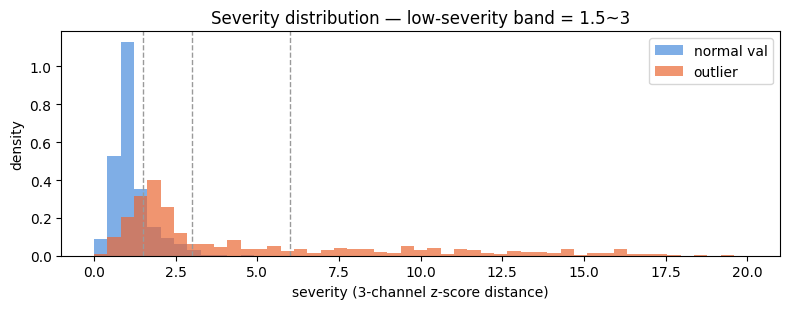

In [17]:
tc = CONFIG["TIME_COL"]; RAW = CONFIG["CHANNELS"]
val_df = normal_p[VAL_MASK].reset_index(drop=True).copy(); out_df = outlier_p.reset_index(drop=True).copy()
# 팀 정의: "normal[AI0, AI1, AI2]의 평균/표준편차" → normal 전체(train+val)로 계산. severity는 모델 입력이 아니라 평가용 구분값이라 누수 문제 없음.
mu_raw, sd_raw = normal_p[RAW].mean(), normal_p[RAW].std()
print("severity 기준 통계 (normal 전체):"); print(pd.DataFrame({"mu": mu_raw, "sigma": sd_raw}).round(4))

def severity(df):
    z = (df[RAW] - mu_raw) / sd_raw
    return np.sqrt((z ** 2).sum(axis=1)).to_numpy()
SEV_BINS = [0, 1.5, 3, 6, 100]; SEV_LABELS = ["low(0-1.5)", "mid(1.5-3)", "high(3-6)", "extreme(6+)"]
for df in [val_df, out_df]:
    df["severity"] = severity(df)
    df["sev_bin"] = pd.cut(df["severity"], bins=SEV_BINS, labels=SEV_LABELS, include_lowest=True).astype(str)
    df["pos"] = df.groupby("seg_id").cumcount()
    df["pos_bin"] = np.where(df["pos"] < 5, "gap 0-4", np.where(df["pos"] < 10, "5-9", "10+"))
LOW_AMP = (pd.Timestamp("2022-07-12 01:00:18"), pd.Timestamp("2022-07-12 01:12:04"))
val_df["mode"] = np.where((val_df[tc] >= LOW_AMP[0]) & (val_df[tc] <= LOW_AMP[1]), "low-amp", "normal-amp")
# phase: 이상 이벤트 시간 3등분 (가정)
out_df["phase"] = pd.qcut(np.arange(len(out_df)), 3, labels=["early", "mid", "late"]).astype(str)

print("outlier severity 분포(행):", out_df["sev_bin"].value_counts().reindex(SEV_LABELS).to_dict())
print("val severity 분포(행)    :", val_df["sev_bin"].value_counts().reindex(SEV_LABELS).fillna(0).astype(int).to_dict())
print("val 운전 상태:", val_df["mode"].value_counts().to_dict(), "| outlier phase:", out_df["phase"].value_counts().to_dict())
fig, ax = plt.subplots(figsize=(8, 3.2))
bins = np.linspace(0, min(out_df.severity.max(), 20), 50)
ax.hist(val_df["severity"], bins, alpha=0.6, color=COLOR["normal"], label="normal val", density=True)
ax.hist(out_df["severity"], bins, alpha=0.7, color=COLOR["outlier"], label="outlier", density=True)
for b in [1.5, 3, 6]: ax.axvline(b, color=COLOR["gray"], ls="--", lw=1)
ax.set_xlabel("severity (3-channel z-score distance)"); ax.set_ylabel("density"); ax.set_title("Severity distribution — low-severity band = 1.5~3"); ax.legend()
fig.tight_layout(); fig.savefig(os.path.join(CONFIG["OUT_DIR"], "team_eval_severity.png"), dpi=130); plt.show()

## 5. 변형 4개(기준선 / 2단계 C / 3단계 P4 / 3단계 P5)의 판정 만들기
3단계 후처리는 그대로 재현한다: P4 = 세그먼트 시작 5행 score×0.5 후 p99 재산정 + 연속 2행, P5 = 3행 이동평균 후 p99 재산정 + 연속 2행.

In [18]:
G_GAP, W_GAP, K_RUN, SMOOTH = 5, 0.5, 2, 3
def tf_gap(df, s): s = s.copy(); s[df["pos"].to_numpy() < G_GAP] *= W_GAP; return s
def tf_smooth(df, s): return pd.Series(s).groupby(df["seg_id"].to_numpy()).transform(lambda x: x.rolling(SMOOTH, min_periods=1).mean()).to_numpy()
def dc_run(above, df, k=K_RUN):
    a = pd.Series(above.astype(int)); grp = (a != a.shift()).cumsum() + (df["seg_id"] != df["seg_id"].shift()).cumsum() * 10_000
    return ((a == 1) & (a.groupby(grp).transform("size") >= k)).to_numpy()

VARIANTS = {}
def add_variant(name, sv, so, tf=None, run=False):
    if tf is not None: sv, so = tf(val_df, sv), tf(out_df, so)
    thr = float(np.percentile(sv, 99)); pv, po = sv >= thr, so >= thr
    if run: pv, po = dc_run(pv, val_df), dc_run(po, out_df)
    VARIANTS[name] = {"pv": pv, "po": po, "sv": sv, "so": so, "thr": thr}
add_variant("기준선 (원본)", sA_v, sA_o)
add_variant("2단계 C pad-aware", sC_v, sC_o)
add_variant("3단계 P4 (갭+연속)", sC_v, sC_o, tf=tf_gap, run=True)
add_variant("3단계 P5 (평활+연속)", sC_v, sC_o, tf=tf_smooth, run=True)
for k, v in VARIANTS.items(): print(f"{k:22s} thr {v['thr']:.4f} | FN {int((~v['po']).sum())} | FP {int(v['pv'].sum())}")

기준선 (원본)               thr 0.5355 | FN 67 | FP 40
2단계 C pad-aware        thr 0.4151 | FN 56 | FP 40
3단계 P4 (갭+연속)          thr 0.3322 | FN 59 | FP 15
3단계 P5 (평활+연속)         thr 0.4444 | FN 48 | FP 34


## 6. 팀 지표 계산

In [19]:
def team_metrics(name, v):
    pv, po, sv, so = v["pv"], v["po"], v["sv"], v["so"]
    y = np.r_[np.zeros(len(pv)), np.ones(len(po))]; pred = np.r_[pv, po].astype(int); s = np.r_[sv, so]
    rec = lambda m: po[m].mean() if m.sum() > 0 else np.nan
    low_mask = (out_df["sev_bin"] == "mid(1.5-3)").to_numpy()
    fpr_mode = {m: pv[(val_df["mode"] == m).to_numpy()].mean() for m in ["low-amp", "normal-amp"]}
    rec_phase = {p: rec((out_df["phase"] == p).to_numpy()) for p in ["early", "mid", "late"]}
    rec_pos = {p: rec((out_df["pos_bin"] == p).to_numpy()) for p in ["gap 0-4", "5-9", "10+"]}
    rec_sev = {b: rec((out_df["sev_bin"] == b).to_numpy()) for b in SEV_LABELS}
    return {"Model": name, "F1": f1_score(y, pred), "PR-AUC": average_precision_score(y, s), "Recall": recall_score(y, pred),
            "FPR": pv.mean() * 100, "Low-sev Recall": rec(low_mask) * 100, "n low-sev rows": int(low_mask.sum()),
            "Worst Mode FPR": max(fpr_mode.values()) * 100, "FPR low-amp": fpr_mode["low-amp"] * 100, "FPR normal-amp": fpr_mode["normal-amp"] * 100,
            "Worst Phase Recall": min(rec_phase.values()) * 100, "Rec early": rec_phase["early"] * 100, "Rec mid": rec_phase["mid"] * 100, "Rec late": rec_phase["late"] * 100,
            "Worst GapPos Recall": min(rec_pos.values()) * 100, "Rec gap0-4": rec_pos["gap 0-4"] * 100,
            **{f"Rec {b}": rec_sev[b] * 100 for b in SEV_LABELS}}

TM = pd.DataFrame([team_metrics(k, v) for k, v in VARIANTS.items()]).set_index("Model")
main = ["F1", "PR-AUC", "Recall", "FPR", "Low-sev Recall", "Worst Mode FPR", "Worst Phase Recall"]
print("=== 팀 통일 지표 (F1↑ PR-AUC↑ Recall↑ FPR↓ Low-sev Recall↑ Worst Mode FPR↓ Worst Phase Recall↑) ==="); display(TM[main].round(3))
print("=== 세부: 운전 상태별 FPR(%) / phase별 recall(%) / 갭 위치별 recall(%) ==="); display(TM[["FPR low-amp", "FPR normal-amp", "Rec early", "Rec mid", "Rec late", "Rec gap0-4", "Worst GapPos Recall"]].round(2))
print("=== severity 구간별 recall(%) — 약한 이상을 잡는가 ==="); display(TM[[f"Rec {b}" for b in SEV_LABELS] + ["n low-sev rows"]].round(1))
TM.round(4).to_csv(os.path.join(CONFIG["OUT_DIR"], "team_metrics_by_stage.csv"))

=== 팀 통일 지표 (F1↑ PR-AUC↑ Recall↑ FPR↓ Low-sev Recall↑ Worst Mode FPR↓ Worst Phase Recall↑) ===


,F1,PR-AUC,Recall,FPR,Low-sev Recall,Worst Mode FPR,Worst Phase Recall
Model,,,,,,,
기준선 (원본),0.909,0.949,0.888,1.003,86.937,3.148,82.0
2단계 C pad-aware,0.919,0.956,0.907,1.003,90.090,3.231,85.5
3단계 P4 (갭+연속),0.936,0.955,0.902,0.376,90.991,1.243,85.5
3단계 P5 (평활+연속),0.931,0.966,0.920,0.852,90.090,2.817,88.0


=== 세부: 운전 상태별 FPR(%) / phase별 recall(%) / 갭 위치별 recall(%) ===


,FPR low-amp,FPR normal-amp,Rec early,Rec mid,Rec late,Rec gap0-4,Worst GapPos Recall
Model,,,,,,,
기준선 (원본),0.07,3.15,87.5,97.0,82.0,73.27,73.27
2단계 C pad-aware,0.04,3.23,88.5,98.0,85.5,74.26,74.26
3단계 P4 (갭+연속),0.00,1.24,87.0,98.0,85.5,71.29,71.29
3단계 P5 (평활+연속),0.00,2.82,90.0,98.0,88.0,76.24,76.24


=== severity 구간별 recall(%) — 약한 이상을 잡는가 ===


,Rec low(0-1.5),Rec mid(1.5-3),Rec high(3-6),Rec extreme(6+),n low-sev rows
Model,,,,,
기준선 (원본),78.2,86.9,97.7,94.6,222
2단계 C pad-aware,81.5,90.1,97.7,94.6,222
3단계 P4 (갭+연속),77.4,91.0,97.7,94.6,222
3단계 P5 (평활+연속),87.9,90.1,97.7,94.6,222


## 7. RFR (Rescue-to-FP ratio) — 단계를 추가할 때 "오경보 1건 감수당 미탐 몇 건 구제"
RFR = (이전 단계 FN 중 새로 탐지한 수) ÷ (새로 생긴 FP 수). 1보다 크면 추가가 이득.

In [20]:
def rfr(prev, new):
    rescued = int(((~prev["po"]) & new["po"]).sum())                 # 이전엔 놓쳤는데 이제 잡은 outlier 행
    lost = int((prev["po"] & (~new["po"])).sum())                    # 이전엔 잡았는데 이제 놓친 행
    new_fp = int(((~prev["pv"]) & new["pv"]).sum())                  # 새로 생긴 FP
    removed_fp = int((prev["pv"] & (~new["pv"])).sum())              # 사라진 FP
    return {"rescued FN": rescued, "newly lost": lost, "new FP": new_fp, "removed FP": removed_fp,
            "RFR": (rescued / new_fp) if new_fp > 0 else np.inf, "net FN": -(rescued - lost), "net FP": new_fp - removed_fp}
pairs = [("기준선 (원본)", "2단계 C pad-aware"), ("2단계 C pad-aware", "3단계 P4 (갭+연속)"), ("2단계 C pad-aware", "3단계 P5 (평활+연속)"), ("기준선 (원본)", "3단계 P4 (갭+연속)")]
RF = pd.DataFrame([{"from → to": f"{a} → {b}", **rfr(VARIANTS[a], VARIANTS[b])} for a, b in pairs]).set_index("from → to")
display(RF)
print("해석: RFR이 inf이면 새 FP 없이 미탐만 구제한 것. 후처리는 FP를 '제거'하는 쪽이라 new FP가 0에 가깝고, 대신 newly lost(새로 놓친 행)를 봐야 한다.")

,rescued FN,newly lost,new FP,removed FP,RFR,net FN,net FP
from → to,,,,,,,
기준선 (원본) → 2단계 C pad-aware,12,1,12,12,1.000000,-11,0
2단계 C pad-aware → 3단계 P4 (갭+연속),4,7,4,29,1.000000,3,-25
2단계 C pad-aware → 3단계 P5 (평활+연속),17,9,12,18,1.416667,-8,-6
기준선 (원본) → 3단계 P4 (갭+연속),13,5,6,31,2.166667,-8,-25


해석: RFR이 inf이면 새 FP 없이 미탐만 구제한 것. 후처리는 FP를 '제거'하는 쪽이라 new FP가 0에 가깝고, 대신 newly lost(새로 놓친 행)를 봐야 한다.


## 8. 그림 — 팀 지표 레이더 대신 막대 비교

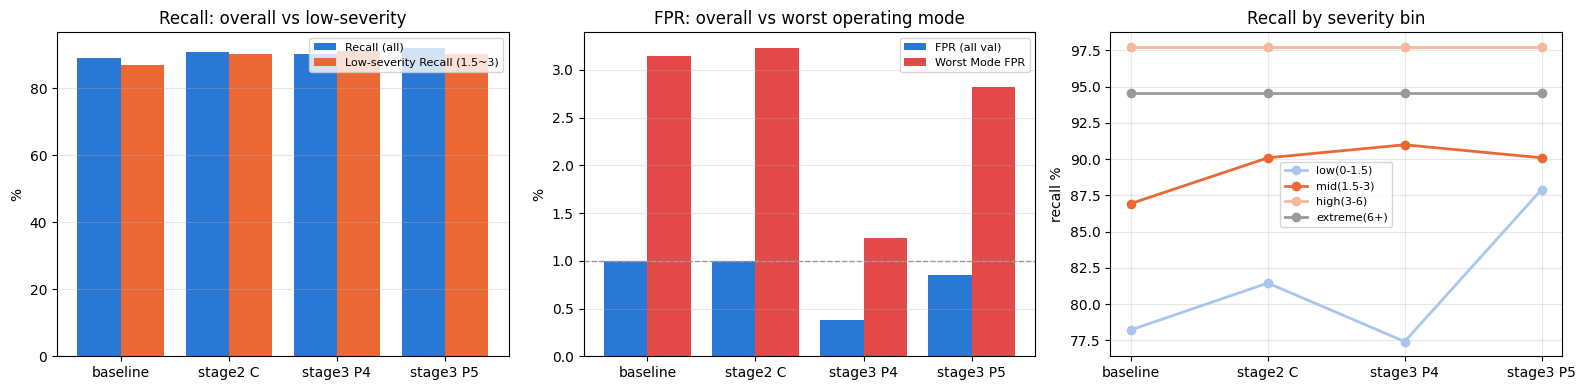

In [21]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
names = list(TM.index); x = np.arange(len(names)); short = ["baseline", "stage2 C", "stage3 P4", "stage3 P5"]
ax = axes[0]; ax.bar(x - 0.2, TM["Recall"] * 100, 0.4, color=COLOR["normal"], label="Recall (all)"); ax.bar(x + 0.2, TM["Low-sev Recall"], 0.4, color=COLOR["outlier"], label="Low-severity Recall (1.5~3)")
ax.set_xticks(x); ax.set_xticklabels(short); ax.set_ylabel("%"); ax.set_title("Recall: overall vs low-severity"); ax.legend(fontsize=8); ax.grid(axis="y", alpha=0.3)
ax = axes[1]; ax.bar(x - 0.2, TM["FPR"], 0.4, color=COLOR["normal"], label="FPR (all val)"); ax.bar(x + 0.2, TM["Worst Mode FPR"], 0.4, color=COLOR["thr"], label="Worst Mode FPR")
ax.axhline(1, color=COLOR["gray"], ls="--", lw=1); ax.set_xticks(x); ax.set_xticklabels(short); ax.set_ylabel("%"); ax.set_title("FPR: overall vs worst operating mode"); ax.legend(fontsize=8); ax.grid(axis="y", alpha=0.3)
ax = axes[2]
for b, c in zip(SEV_LABELS, ["#a9c7ee", COLOR["outlier"], "#f5b899", COLOR["gray"]]):
    ax.plot(short, TM[f"Rec {b}"], marker="o", lw=2, color=c, label=b)
ax.set_ylabel("recall %"); ax.set_title("Recall by severity bin"); ax.legend(fontsize=8); ax.grid(alpha=0.3)
fig.tight_layout(); fig.savefig(os.path.join(CONFIG["OUT_DIR"], "team_eval_by_stage.png"), dpi=130); plt.show()

### 해석 (실행 결과, severity = normal 전체 기준)

| Model | F1 ↑ | PR-AUC ↑ | Recall ↑ | FPR ↓ | Low-sev Recall ↑ | Worst Mode FPR ↓ | Worst Phase Recall ↑ |
|---|---|---|---|---|---|---|---|
| PatchTST 기준선 | 0.909 | 0.949 | 0.888 | 1.00% | 86.9% | 3.15% | 82.0% |
| PatchTST + pad-aware | 0.919 | 0.956 | 0.907 | 1.00% | 90.1% | 3.23% | 85.5% |
| **PatchTST + pad-aware + 후처리 P4** | **0.936** | 0.955 | 0.902 | **0.38%** | **91.0%** | **1.24%** | 85.5% |
| PatchTST + pad-aware + 후처리 P5 | 0.931 | **0.966** | **0.920** | 0.85% | 90.1% | 2.82% | **88.0%** |

- 단계 순서는 모든 지표에서 불변: 기준선 < pad-aware < 후처리.
- P4는 오경보(Worst Mode FPR 1.24%, FPR 0.38%)와 Low-sev Recall(91.0%)에서, P5는 Recall(0.920)·PR-AUC·Worst Phase Recall(88.0%)·가장 약한 구간(sev 0~1.5) recall(87.9%)에서 우세. 팀 평가 방향 문구에는 P4가 더 부합.
- outlier 600행 중 124행은 severity 0~1.5(진폭으로는 정상처럼 보임). z-score 류 방법은 원리적으로 못 잡는 행인데 PatchTST는 77~88% 탐지 → 시간 패턴 기반의 강점.
- RFR: 기준선 → pad-aware 1.0(미탐 12 구제, FP 12 생기고 12 사라져 net 0), pad-aware → P4는 FP 제거형이라 RFR보다 net FN +3 / net FP −25로 읽어야 함. 기준선 → P4 전체 RFR 2.17.
- 팀 모델과 직접 비교 전 통일할 것: 데이터 분할, 임계값 규칙, window 길이(30 vs 32), phase 정의(여기선 이벤트 3등분 가정). severity 기준은 팀 정의(normal 전체)와 맞춤.
